In [79]:
#Mount your drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Code

Download and save the file weight-height.csv into your drive (from https://www.kaggle.com/mustafaali96/weight-height)

With that dataset,  plot histograms, kernel density estimation and Gaussian distribution with MLE for the followings:


*   Height all
*   Height Male
*   Height Female
*   Weight all
*   Weight Male
*   Weight Female

For the histograms, you can use any module. However, you have to implement from scratch the code for the kernel density estimation and Gaussian distribution with MLE (you cannot use any specialized library to compute it.) To plot, you can use any library you want.

In [80]:
##Code here your own implementation
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/drive/MyDrive/MachineLearning/HW4/weight-height.csv")

print(df)

      Gender     Height      Weight
0       Male  73.847017  241.893563
1       Male  68.781904  162.310473
2       Male  74.110105  212.740856
3       Male  71.730978  220.042470
4       Male  69.881796  206.349801
...      ...        ...         ...
9995  Female  66.172652  136.777454
9996  Female  67.067155  170.867906
9997  Female  63.867992  128.475319
9998  Female  69.034243  163.852461
9999  Female  61.944246  113.649103

[10000 rows x 3 columns]


In [81]:
# the code for the kernel density estimation
import numpy as np

def kernel_function(u):
  return(1/np.sqrt(2*np.pi)) * np.exp(-0.5*u**2)

def bandwidth(data):
  n=len(data)
  sigma=np.std(data,ddof=1)
  return 1.06*sigma * n**(-1/5)

def kde(x_points, data, bandwidth):
  n = len(data)
  densities = np.zeros_like(x_points)
  for xi in data:
    densities += kernel_function((x_points - xi)/bandwidth)
  densities /= (n * bandwidth)
  return densities

def mle(data):
  mu=np.mean(data)
  sigma2=np.mean((data-mu)**2)
  sigma=np.sqrt(sigma2)
  return mu, sigma

def pdf(x, mu, sigma):
  return (1/(np.sqrt(2*np.pi)*sigma)) * np.exp(-((x-mu)**2)/(2*sigma**2))

In [82]:
height_all=df["Height"].values
height_male=df[df["Gender"]=="Male"]["Height"].values
height_female=df[df["Gender"]=="Female"]["Height"].values

weight_all=df["Weight"].values
weight_male=df[df["Gender"]=="Male"]["Weight"].values
weight_female=df[df["Gender"]=="Female"]["Weight"].values

In [124]:
def show_result(data, title):
    x_points=np.linspace(np.min(data), np.max(data), 200)
    h=bandwidth(data)
    kde_density=kde(x_points, data, h)

    mu, sigma=mle(data)
    pdf_mle=pdf(x_points, mu, sigma)

    plt.hist(data, density=True, label="Histogram")
    plt.plot(x_points, kde_density, label="KDE")
    plt.plot(x_points, pdf_mle, label="MLE with Gaussian")
    plt.title(title)
    plt.legend()
    plt.show()

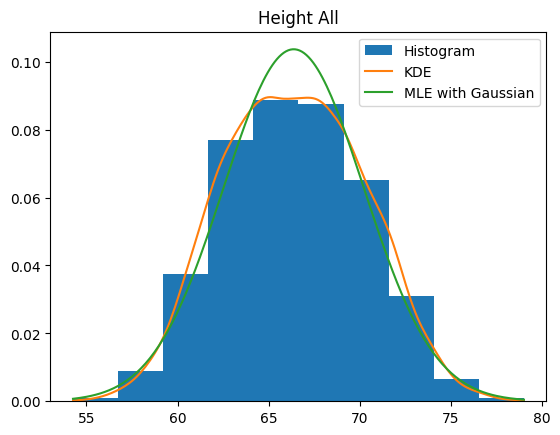

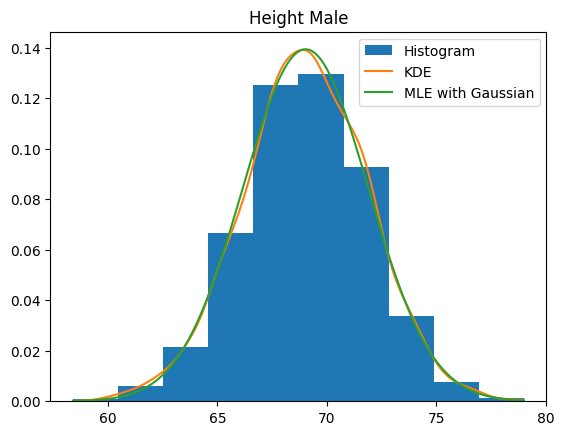

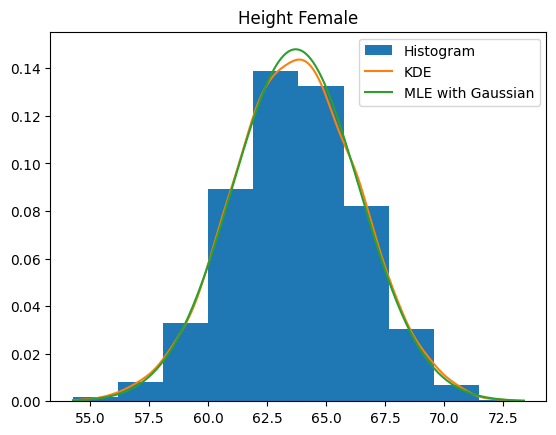

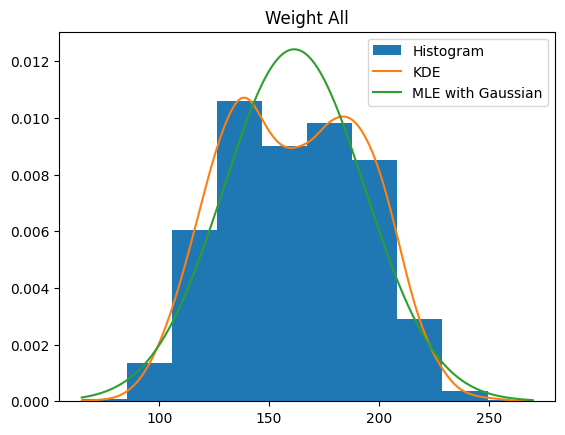

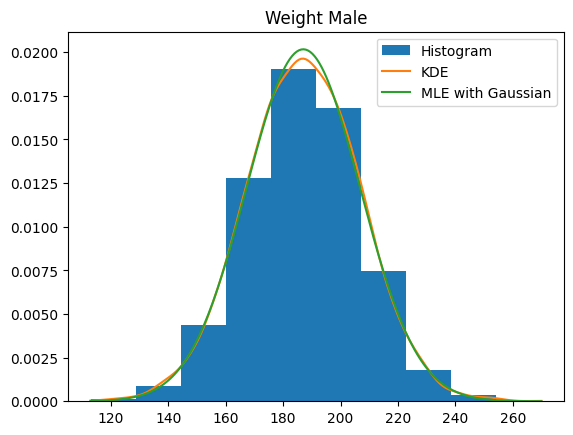

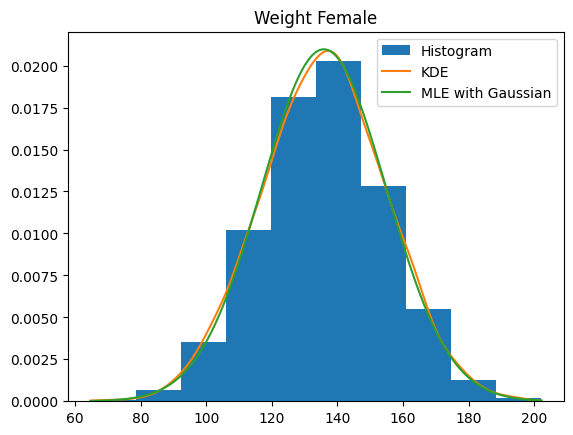

In [125]:
#height
show_result(height_all, "Height All")
show_result(height_male, "Height Male")
show_result(height_female, "Height Female")

#weight
show_result(weight_all, "Weight All")
show_result(weight_male, "Weight Male")
show_result(weight_female, "Weight Female")

# Report

1.   Why do we need to apply these kinds of distribution estimations, in general terms? What kind of in formation can they provide and how can we use it?
2.   Explain the parameters you chose for the histogram plot. Why did you choose these ones? Which criteria did you follow?
3.   Explain the parameters you chose for the KDE and Gaussian plot. Why did you choose these ones? Which criteria did you follow?
4.   Do you observe any distribution having more than one peak? Which ones? What does it mean?
5.   Make a case with pros and cons of each estimation method. Why can we conclude there is no one 'perfect' method for these estimations?
6.   Conclude with some thoughts and things you learned from this homework.

1. It is needed to understand the overall distribution of the data. Just looking at the histogram only shows the rough frequency, but by applying KDE and MLE with Gaussian we can know not just the size of values but also which range the data are crowded in, and understand some characteristics of the data.

2. "density=True" It was used to display the histogram in the form of a probability density.
This way, it can be compared on the same scale as the KDE or Gaussian curve.

3. For the KDE, I used a Gaussian kernel and the bandwidth was calculated using Silverman’s rule of thumb. This rule automatically adjusts the smoothness depending on the sample size and standard deviation, so it makes the curve not too rough and not too flat. For the Gaussian distribution, I used the mean and standard deviation estimated by MLE. These parameters represent the normal distribution that best fits the data.

4. In the case of Height All and Weight All, there are two peaks. This happens because male and female data are mixed together. When the data are separated by gender, each distribution shows only one peak, which means that the height and weight of each gender are close to a normal distribution.

5. Each method has its own advantages and disadvantages.
The histogram is simple and easy to understand, but the result can change depending on the bin size.
KDE gives a smooth and continuous shape, showing the real pattern of the data better, but it depends a lot on the bandwidth value.
The Gaussian distribution with MLE is mathematically clear and easy to interpret with mean and standard deviation, but it doesn't work well if the data are not normally distributed.

6. Through this homework, I learned how to implement KDE and MLE by myself and understand how the bandwidth changes the smoothness of the curve.
I also found that when male and female data are mixed, the distribution becomes bimodal. From this, I realized the importance of understanding the real shape of data, not just drawing graphs but analyzing what they mean.

** I used GenAI to unnatural parts of my English.